In [16]:
# Evaluation library
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.model_selection import GridSearchCV

# Deep Learning libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, Dropout
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

# Scikit-learn wrapper for Keras
from scikeras.wrappers import KerasClassifier

In [17]:
# Load MNIST handwritten digit dataset
(X_train_digit, y_train_digit), (X_test_digit, y_test_digit) =keras.datasets.fashion_mnist.load_data()
print("Training images:", X_train_digit.shape)
print("Training labels:", y_train_digit.shape)
print("Testing images:", X_test_digit.shape)
print("Testing labels:", y_test_digit.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [18]:
X_train_digit

array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       ...,

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [19]:
y_train_digit

array([9, 0, 0, ..., 3, 0, 5], shape=(60000,), dtype=uint8)

In [20]:
 X_train_digit[1]

array([[  0,   0,   0,   0,   0,   1,   0,   0,   0,   0,  41, 188, 103,
         54,  48,  43,  87, 168, 133,  16,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   1,   0,   0,   0,  49, 136, 219, 216, 228, 236,
        255, 255, 255, 255, 217, 215, 254, 231, 160,  45,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,  14, 176, 222, 224, 212, 203, 198, 196,
        200, 215, 204, 202, 201, 201, 201, 209, 218, 224, 164,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0, 188, 219, 200, 198, 202, 198, 199, 199,
        201, 196, 198, 198, 200, 200, 200, 200, 201, 200, 225,  41,   0,
          0,   0],
       [  0,   0,   0,   0,  51, 219, 199, 203, 203, 212, 238, 248, 250,
        245, 249, 246, 247, 252, 248, 235, 207, 203, 203, 222, 140,   0,
          0,   0],
       [  0,   0,   0,   0, 116, 226, 206, 204, 207, 204, 101,  75,  47,
         73,  48,  50,  45,  51,  63, 113, 222, 202, 206, 220, 224,   0,
          0,   0],
       [  

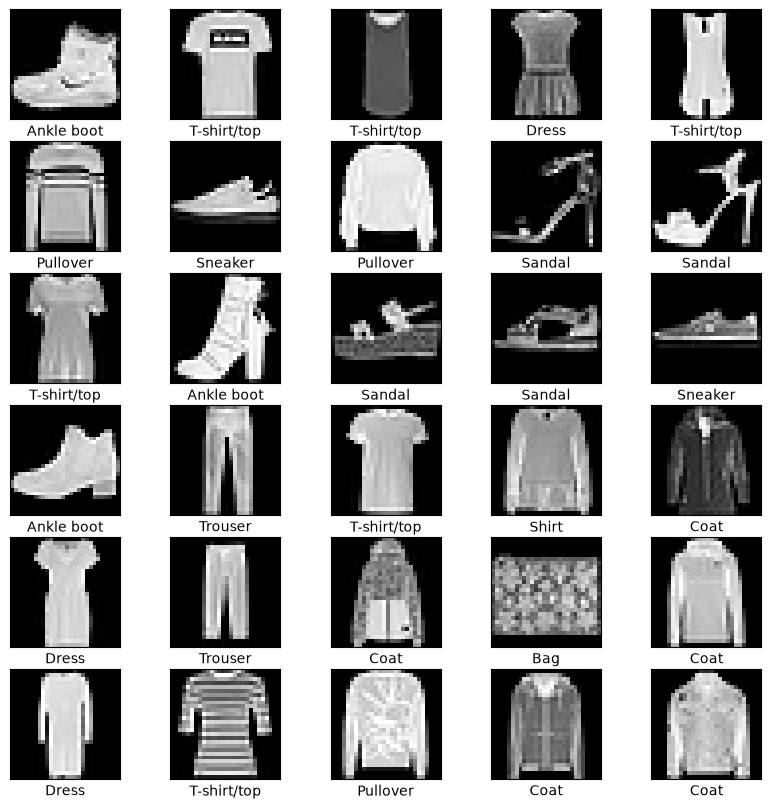

In [21]:
import matplotlib.pyplot as plt

# Names of numbers in the dataset in order
col_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# Visualizing the digits
plt.figure(figsize=(10, 10))

for i in range(30):
    plt.subplot(6, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(X_train_digit[i], cmap='gray')
    plt.xlabel(col_names[y_train_digit[i]])

plt.show()

In [22]:
X_train_digit.shape

(60000, 28, 28)

In [23]:
X_test_digit.shape

(10000, 28, 28)

In [24]:
X_train_digit = X_train_digit.reshape(60000, 784)
X_test_digit = X_test_digit.reshape(10000, 784)

In [25]:
X_train_digit.shape

(60000, 784)

In [26]:
X_train_digit

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(60000, 784), dtype=uint8)

In [27]:
y_train_digit.shape

(60000,)

In [28]:
# Encoding Digit MNIST Labels
y_train_digit = to_categorical(y_train_digit, num_classes=10)

y_test_digit = to_categorical(y_test_digit, num_classes=10)

In [29]:
y_train_digit.shape

(60000, 10)

In [30]:
y_train_digit

array([[0., 0., 0., ..., 0., 0., 1.],
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(60000, 10))

In [31]:
y_test_digit

array([[0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(10000, 10))

In [32]:
# Creating base neural network
model = keras.Sequential([
    layers.Dense(256, activation='relu', input_shape=(784,)),
    layers.Dropout(0.3),
    # layers.BatchNormalization(),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    # layers.BatchNormalization(),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    # layers.BatchNormalization(),

    layers.Dense(10, activation='softmax'),
])

C:\Users\Gayathri R\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
# Compiling the model
model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=['accuracy']
)

In [34]:
# Training the model
history = model.fit(
    X_train_digit,
    y_train_digit,
    batch_size=100,
    epochs=10,
    validation_data=(X_test_digit, y_test_digit)
)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.1052 - loss: 3.9591 - val_accuracy: 0.1001 - val_loss: 2.3026
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.0998 - loss: 2.3073 - val_accuracy: 0.1049 - val_loss: 2.2917
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.1030 - loss: 2.3008 - val_accuracy: 0.1074 - val_loss: 2.2878
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.1049 - loss: 2.2900 - val_accuracy: 0.1181 - val_loss: 2.2739
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.1125 - loss: 2.2840 - val_accuracy: 0.1315 - val_loss: 2.2397
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.1231 - loss: 2.2521 - val_accuracy: 0.1345 - val_loss: 2.2193
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.1231 - loss: 2.2513 - val_accuracy: 0.1160 - val_loss: 2.2662
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.1281 - loss: 2.2437 - val_accurac

In [35]:
# Predicting the labels - DIGIT
y_predict = model.predict(X_test_digit)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [36]:
y_predict

array([[0.10547356, 0.10509233, 0.10410669, ..., 0.10180224, 0.10438503,
        0.10285176],
       [0.10547356, 0.10509233, 0.10410669, ..., 0.10180224, 0.10438503,
        0.10285176],
       [0.10547356, 0.10509233, 0.10410669, ..., 0.10180224, 0.10438503,
        0.10285176],
       ...,
       [0.10547356, 0.10509233, 0.10410669, ..., 0.10180224, 0.10438503,
        0.10285176],
       [0.10547356, 0.10509233, 0.10410669, ..., 0.10180224, 0.10438503,
        0.10285176],
       [0.10547356, 0.10509233, 0.10410669, ..., 0.10180224, 0.10438503,
        0.10285176]], shape=(10000, 10), dtype=float32)

In [37]:
y_predict[0]

array([0.10547356, 0.10509233, 0.10410669, 0.10447306, 0.1045391 ,
       0.06254964, 0.1047266 , 0.10180224, 0.10438503, 0.10285176],
      dtype=float32)

In [38]:
import numpy as np
# Get the index of the maximum value in the predicted vector
y_predicts = np.argmax(y_predict, axis=1)

In [39]:
y_predicts[0]

np.int64(0)

In [40]:
# Get the actual labels from the one-hot encoded vectors
y_test_digit_eval = np.argmax(y_test_digit, axis=1)

In [41]:
y_test_digit_eval 

array([9, 2, 1, ..., 8, 1, 5], shape=(10000,))

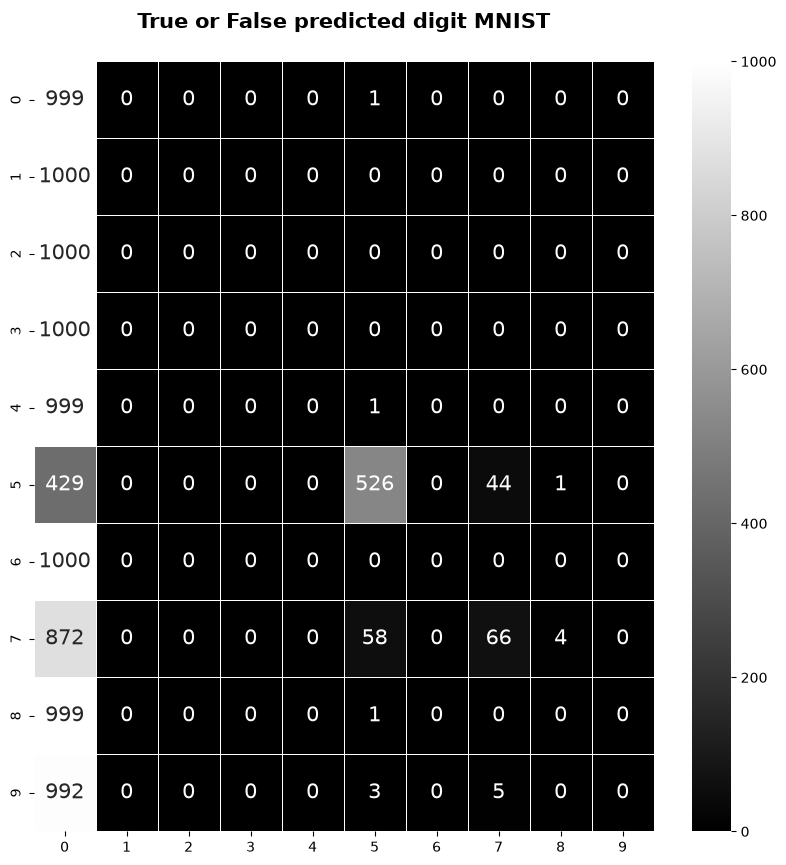

In [42]:
import seaborn as sns
# Confusion matrix for Digit MNIST
con_mat = confusion_matrix(y_test_digit_eval, y_predicts)

plt.style.use('seaborn-v0_8-deep')
plt.figure(figsize=(10, 10))

sns.heatmap(
    con_mat,
    annot=True,
    annot_kws={'size': 15},
    linewidths=0.5,
    fmt='d',
    cmap='gray'
)

plt.title(
    'True or False predicted digit MNIST\n',
    fontweight='bold',
    fontsize=15
)

plt.show()

In [43]:
from sklearn.metrics import classification_report

print(classification_report(y_test_digit_eval, y_predicts))

              precision    recall  f1-score   support

           0       0.11      1.00      0.19      1000
           1       0.00      0.00      0.00      1000
           2       0.00      0.00      0.00      1000
           3       0.00      0.00      0.00      1000
           4       0.00      0.00      0.00      1000
           5       0.89      0.53      0.66      1000
           6       0.00      0.00      0.00      1000
           7       0.57      0.07      0.12      1000
           8       0.00      0.00      0.00      1000
           9       0.00      0.00      0.00      1000

    accuracy                           0.16     10000
   macro avg       0.16      0.16      0.10     10000
weighted avg       0.16      0.16      0.10     10000



C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


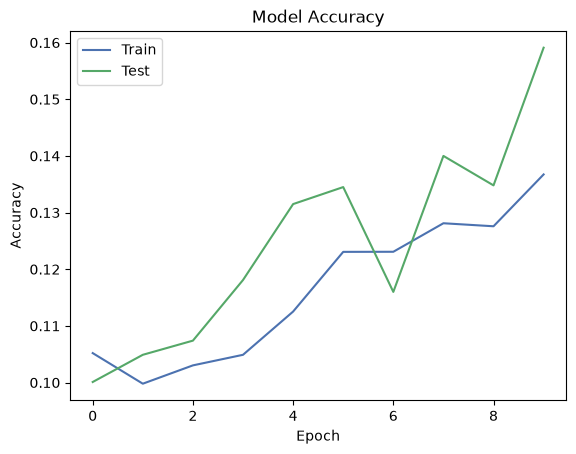

In [44]:
# Summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')

plt.legend(['Train', 'Test'], loc='best')
plt.show()

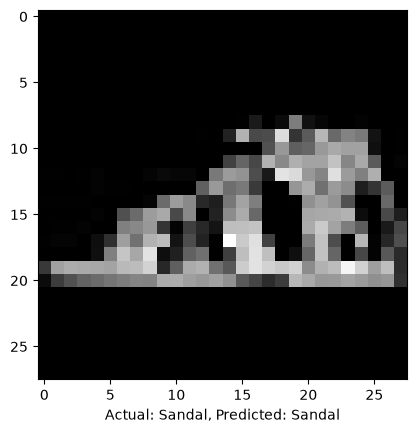

In [54]:
col_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

index = 11

plt.imshow(X_test_digit[index].reshape(28, 28), cmap='gray')

actual = y_test_digit_eval[index]
predicted = y_predicts[index]

plt.xlabel(
    "Actual: {}, Predicted: {}".format(
        col_names[int(actual)],
        col_names[int(predicted)]
    )
)

plt.show()